In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

El contrato fija la entrega del proyecto en la semana 27, con una penalización de 6 k€ por cada semana de retraso. Se adjuntan las prelaciones, la duración normal y la tope de cada actividad (semanas) y su coste unitario de reducción (k€/semana). Las actividades B, E no pueden acelerarse.

In [4]:
pregunta_1 = "1. Determine la duración del proyecto con las duraciones normales y la penalización a la que se expone si no se reduce.  "
pregunta_2 = "2. Aplique el algoritmo de Ackoff-Sasieni para llevar el proyecto a la semana 27, anotando el sobrecoste de cada paso.  "
pregunta_3 = "3. Compare en cada paso el sobrecoste con la penalización evitada y decida cuántas semanas conviene reducir. ¿Cuál es el coste total mínimo (sobrecoste más penalización)?  "
pregunta_4 = "4. ¿Qué habría cambiado si las actividades no acelerables hubieran sido críticas? Compruébelo sobre el camino crítico.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Determine la duración del proyecto con las duraciones normales y la penalización a la que se expone si no se reduce.  

2. Aplique el algoritmo de Ackoff-Sasieni para llevar el proyecto a la semana 27, anotando el sobrecoste de cada paso.  

3. Compare en cada paso el sobrecoste con la penalización evitada y decida cuántas semanas conviene reducir. ¿Cuál es el coste total mínimo (sobrecoste más penalización)?  

4. ¿Qué habría cambiado si las actividades no acelerables hubieran sido críticas? Compruébelo sobre el camino crítico.  

In [5]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, cap_duration, ucr   
    ('A'     , '---'      , 5       , 4           , 9     ),
    ('B'     , '---'      , 2       , 2           , np.inf),
    ('C'     , '---'      , 5       , 2           , 4     ),
    ('D'     , 'B,C'      , 7       , 4           , 4     ),
    ('E'     , 'A,B'      , 8       , 8           , np.inf),
    ('F'     , 'D,E'      , 7       , 5           , 5     ),
    ('G'     , 'F'        , 3       , 1           , 9     ),
    ('H'     , 'F'        , 7       , 4           , 1     ),
    ('I'     , 'G'        , 6       , 4           , 6     ),
], columns=['activity', 'predecessor', 'duration', 'cap_duration', 'ucr']).set_index('activity')
datos_enunciado

,predecessor,duration,cap_duration,ucr
activity,,,,
A,---,5,4,9.0
B,---,2,2,inf
C,---,5,2,4.0
D,"B,C",7,4,4.0
E,"A,B",8,8,inf
F,"D,E",7,5,5.0
G,F,3,1,9.0
H,F,7,4,1.0
I,G,6,4,6.0


# Resolución

In [6]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()

## Apartado 1

In [7]:
display(Markdown(pregunta_1))

1. Determine la duración del proyecto con las duraciones normales y la penalización a la que se expone si no se reduce.  

In [ ]:
proyecto.display_pert_pasos(datos_proyecto['duration'])

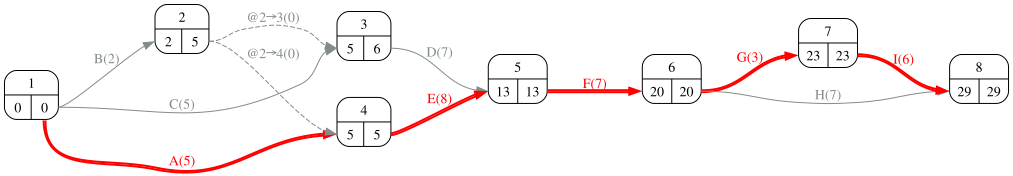

In [8]:
#| fig-cap: "Grafo PERT con las duraciones normales y el camino crítico"
#| label: fig-pert
proyecto.pert(durations=datos_proyecto['duration'], ranksep=1)

In [9]:
plazo_contrato, penalizacion_semanal = 27, 6
duracion_normal = proyecto.duration(datos_proyecto['duration'])
camino_critico = proyecto.display_critical_path(datos_proyecto['duration'])
retraso = max(0, duracion_normal - plazo_contrato)
Markdown(f'Con las duraciones normales el proyecto dura {duracion_normal} semanas, {retraso} más que el plazo: '
         f'penalización de {retraso} × {penalizacion_semanal} = {retraso * penalizacion_semanal} k€.')

- Route_1 :	A, E, F, G, I <br> 

Con las duraciones normales el proyecto dura 29 semanas, 2 más que el plazo: penalización de 2 × 6 = 12 k€.

## Apartado 2

In [10]:
display(Markdown(pregunta_2))

2. Aplique el algoritmo de Ackoff-Sasieni para llevar el proyecto a la semana 27, anotando el sobrecoste de cada paso.  

En cada paso del algoritmo de Ackoff-Sasieni se acorta una semana la ruta (o rutas) crítica(s) eligiendo, entre las actividades críticas con margen, la combinación de menor CUR que reduzca *todas* las rutas críticas a la vez. Cuando hay varias rutas críticas sin actividades comunes baratas hay que acortar una actividad de cada una, y el coste del paso es la suma. La tabla muestra, para cada ruta, el CUR de sus actividades y su duración tras cada paso; las últimas filas, el margen de reducción que le queda a cada actividad.

In [11]:
#| tbl-cap: "Algoritmo de Ackoff-Sasieni"
#| label: tbl-ackoff
tabla_ackoff, pasos, duraciones_reducidas, margen_restante = proyecto.ackoff(
    durations=datos_proyecto['duration'], min_durations=datos_proyecto['cap_duration'],
    costs=datos_proyecto['ucr'], reduction=2, report=False)
tabla_ackoff

,A,B,C,D,E,F,G,H,I,0,1,2
Route_1,9.0,,,,inf,5.0,9.0,,6.0,29.0,28.0,27.0
Route_2,9.0,,,,inf,5.0,,1.0,,27.0,26.0,25.0
Route_3,,inf,,4.0,,5.0,9.0,,6.0,25.0,24.0,23.0
Route_4,,inf,,4.0,,5.0,,1.0,,23.0,22.0,21.0
Route_5,,inf,,,inf,5.0,9.0,,6.0,26.0,25.0,24.0
Route_6,,inf,,,inf,5.0,,1.0,,24.0,23.0,22.0
Route_7,,,4.0,4.0,,5.0,9.0,,6.0,28.0,27.0,26.0
Route_8,,,4.0,4.0,,5.0,,1.0,,26.0,25.0,24.0
0,1.0,0.0,3.0,3.0,0.0,2.0,2.0,3.0,2.0,,,
1,1.0,0.0,3.0,3.0,0.0,1.0,2.0,3.0,2.0,,,


Lo que se compara en cada paso: las rutas críticas en ese momento, las opciones que acortan todas a la vez (una actividad común con margen, o una pareja con una actividad de cada ruta) con su coste, y la elegida (la más barata).

In [12]:
#| tbl-cap: "Opciones consideradas en cada paso de Ackoff-Sasieni"
#| label: tbl-ackoffPaso
detalle_ackoff(proyecto, datos_proyecto['duration'], datos_proyecto['cap_duration'], datos_proyecto['ucr'], pasos)

,duración,rutas críticas,opciones (coste),elegida,coste del paso
paso,,,,,
1,29,Route_1,F (5); I (6); A (9); G (9),F,5.0
2,28,Route_1,F (5); I (6); A (9); G (9),F,5.0


In [13]:
resumen = pd.DataFrame({'actividades acortadas': [', '.join(acts) for acts in pasos.values()],
                        'sobrecoste del paso': [sum(datos_proyecto.loc[acts, 'ucr']) for acts in pasos.values()]},
                       index=pd.Index(range(1, len(pasos) + 1), name='paso'))
resumen['duración'] = duracion_normal - resumen.index
resumen['sobrecoste acumulado'] = resumen['sobrecoste del paso'].cumsum()
resumen

,actividades acortadas,sobrecoste del paso,duración,sobrecoste acumulado
paso,,,,
1,F,5.0,28,5.0
2,F,5.0,27,10.0


## Apartado 3

In [14]:
display(Markdown(pregunta_3))

3. Compare en cada paso el sobrecoste con la penalización evitada y decida cuántas semanas conviene reducir. ¿Cuál es el coste total mínimo (sobrecoste más penalización)?  

In [15]:
decision = resumen.copy()
decision['penalización evitada'] = penalizacion_semanal
decision['conviene'] = decision['sobrecoste del paso'] < penalizacion_semanal
decision['coste total (sobrecoste + penalización)'] = decision['sobrecoste acumulado'] + penalizacion_semanal * (decision['duración'] - plazo_contrato).clip(lower=0)
decision

,actividades acortadas,sobrecoste del paso,duración,sobrecoste acumulado,penalización evitada,conviene,coste total (sobrecoste + penalización)
paso,,,,,,,
1,F,5.0,28,5.0,6,True,11.0
2,F,5.0,27,10.0,6,True,10.0


In [16]:
sin_reducir = penalizacion_semanal * retraso
mejor = decision['coste total (sobrecoste + penalización)'].idxmin()
coste_mejor = decision.loc[mejor, 'coste total (sobrecoste + penalización)']
Markdown(f'''Sin reducir, la penalización sería de {sin_reducir} k€. Conviene dar cada paso mientras su sobrecoste sea menor que la penalización de la semana que evita ({penalizacion_semanal} k€); el coste total mínimo es {coste_mejor:.0f} k€ y se alcanza reduciendo {mejor} semana(s), hasta una duración de {duracion_normal - mejor} semanas.''')

Sin reducir, la penalización sería de 12 k€. Conviene dar cada paso mientras su sobrecoste sea menor que la penalización de la semana que evita (6 k€); el coste total mínimo es 10 k€ y se alcanza reduciendo 2 semana(s), hasta una duración de 27 semanas.

## Apartado 4

In [17]:
display(Markdown(pregunta_4))

4. ¿Qué habría cambiado si las actividades no acelerables hubieran sido críticas? Compruébelo sobre el camino crítico.  

In [18]:
no_acelerables = datos_proyecto.index[np.isinf(datos_proyecto['ucr'])].tolist()
criticas = sorted(set(a for acts in proyecto.critical_path(datos_proyecto['duration']).values() for a in acts))
en_critico = [a for a in no_acelerables if a in criticas]
Markdown(f'''Las actividades no acelerables son {", ".join(no_acelerables)}; de ellas, {", ".join(en_critico) or "ninguna"} está en el camino crítico. Una actividad no acelerable en el camino crítico no impide reducir el proyecto mientras haya otras actividades críticas con margen, pero cuando todas las rutas críticas pasan por actividades sin margen la duración tope queda fijada y ninguna cantidad de dinero la rebaja.''')

Las actividades no acelerables son B, E; de ellas, E está en el camino crítico. Una actividad no acelerable en el camino crítico no impide reducir el proyecto mientras haya otras actividades críticas con margen, pero cuando todas las rutas críticas pasan por actividades sin margen la duración tope queda fijada y ninguna cantidad de dinero la rebaja.